# Issue #324 — Top-2 N7 full factorial

Executed decision notebook; issue is the independent unit.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/top2_factorial'

In [2]:
decision=json.loads((OUT/'decision.json').read_text())
perf=pd.read_csv(OUT/'performance.csv')
effects=pd.read_csv(OUT/'factorial_effects.csv')
matched=pd.read_csv(OUT/'matched_performance.csv')
decision

{'claim_boundary': 'RETROSPECTIVE_COMPLETE_CASE_EXPLORATION',
 'contract': 'BJ-UNIFIED-TOP2-FACTORIAL-001/v1',
 'descriptive_joint_positive_both_years': ['S1O1A0', 'S1O1A1'],
 'disposition': 'NO_INCREMENT',
 'ex_largest_required': True,
 'issue': 324,
 'joint_positive_both_years': [],
 'promotion': False,
 'standalone_positive_both_years': [],
 'unlock_210': False}

In [3]:
perf[(perf.horizon=='10h')][['issue_year','cell','capital_return','conservative_capital_return','hit_rate']].sort_values(['issue_year','cell'])

,issue_year,cell,capital_return,conservative_capital_return,hit_rate
0,2023,S0O0A0,-0.060981,-0.086581,0.186047
1,2023,S0O0A1,-0.060981,-0.086581,0.186047
2,2023,S0O1A0,-0.077385,-0.102985,0.046512
3,2023,S0O1A1,-0.092693,-0.118293,0.046512
4,2023,S1O0A0,0.007468,-0.007892,0.191489
5,2023,S1O0A1,0.007468,-0.007892,0.191489
6,2023,S1O1A0,0.022821,0.007461,0.085106
7,2023,S1O1A1,0.020091,0.004731,0.085106
8,2024,S0O0A0,0.035673,0.015193,0.344828
9,2024,S0O0A1,0.106387,0.085907,0.344828


In [4]:
effects[effects.horizon.eq('10h')].pivot(index='effect',columns='issue_year',values='mean')

issue_year,2023,2024
effect,,
A_main,0.000000,126.137845
O_main,-39.055741,164.752042
OxA,-36.449197,-86.694353
S_main,170.825723,-92.382634
SxA,0.000000,-84.120222
SxO,26.020374,185.278264
SxOxA,29.949570,194.940159


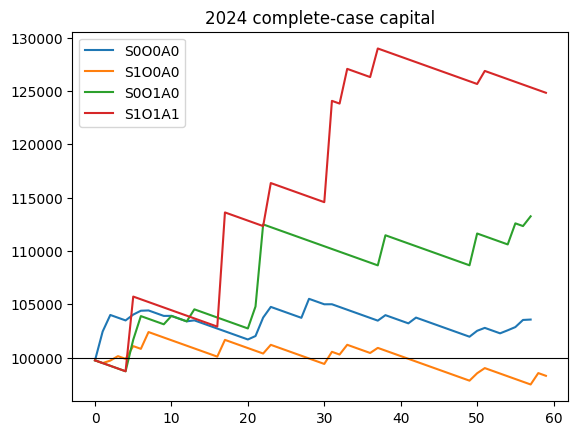

In [5]:
paths=pd.read_csv(OUT/'capital_paths.csv')
for cell in ['S0O0A0','S1O0A0','S0O1A0','S1O1A1']:
 g=paths[(paths.horizon=='10h')&(paths.issue_year==2024)&(paths.cell==cell)]
 plt.plot(range(len(g)),g.capital_after,label=cell)
plt.axhline(100000,color='black',lw=.8);plt.legend();plt.title('2024 complete-case capital');plt.show()